# Power BI dashboard – reference mock-up and KPI check

**Video 8.4** · ShopKart project

**Goal:** Compute the exact KPI values your Power BI dashboard should show, and draw a static picture of the target dashboard layout.

**How to open in Colab:** go to colab.research.google.com → File → Upload notebook → choose this file. Then click the folder icon on the left and drag these data files in: `shopkart_clean.csv`. Then run cells from top to bottom (Shift + Enter).

This notebook is for checking your work. Build the real dashboard in Power BI Desktop by following `M08_8.4_PowerBI_Dashboard_Build_Guide.docx`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
df = pd.read_csv("shopkart_clean.csv")
os.makedirs("images", exist_ok=True)
MAIN, HIGHLIGHT, GREY = "#2a78d6", "#eb6834", "#b8b6ae"

## 1. The five KPIs (no slicer selected)

In [2]:
def kpis(d):
    return pd.Series({
        "Total Revenue (₹)": round(d["revenue"].sum(), 2),
        "Total Orders": len(d),
        "Return Rate %": round(d["returned"].eq("Y").mean() * 100, 2),
        "Avg Rating": round(d["rating"].mean(), 2),       # blanks are ignored, like AVERAGE in Power BI
        "Total Profit (₹)": round(d["profit"].sum(), 2),
    })

kpis(df)

Total Revenue (₹)    14704649.70
Total Orders             5000.00
Return Rate %              13.74
Avg Rating                  3.96
Total Profit (₹)      3140749.70
dtype: float64

## 2. KPIs when a slicer is selected
Click these slicer values in Power BI and compare.

In [3]:
checks = {
    "All data": df,
    "City = Pune": df[df["city"] == "Pune"],
    "City = Delhi": df[df["city"] == "Delhi"],
    "Membership = Prime": df[df["membership"] == "Prime"],
    "Membership = Free": df[df["membership"] == "Free"],
    "Pune + Prime": df[(df["city"] == "Pune") & (df["membership"] == "Prime")],
}
pd.DataFrame({name: kpis(d) for name, d in checks.items()}).T

,Total Revenue (₹),Total Orders,Return Rate %,Avg Rating,Total Profit (₹)
All data,14704649.70,5000.0,13.74,3.96,3140749.70
City = Pune,1387698.30,451.0,32.37,3.47,284208.30
City = Delhi,2323405.40,804.0,10.20,4.04,499835.40
Membership = Prime,7926790.15,2702.0,13.25,3.95,1714510.15
Membership = Free,6777859.55,2298.0,14.32,3.97,1426239.55
Pune + Prime,633460.05,224.0,29.46,3.47,136490.05


## 3. Numbers behind each visual

In [4]:
print((df.groupby("category")["revenue"].sum().sort_values(ascending=False)).round(2), "\n")
print((df.groupby("order_month")["revenue"].sum()).round(2), "\n")
print((df.groupby("city")["revenue"].sum().sort_values(ascending=False)).round(2))

category
Electronics    7331018.05
Fashion        3121345.60
Home           2655047.30
Beauty          877640.35
Books           719598.40
Name: revenue, dtype: float64 

order_month
1     1073267.05
2      863479.50
3     1080121.85
4      983480.60
5      786912.00
6      793841.15
7      873631.50
8     1203393.25
9     1543639.40
10    1978317.00
11    1965664.35
12    1558902.05
Name: revenue, dtype: float64 

city
Delhi        2323405.40
Bengaluru    2256613.25
Mumbai       2090206.00
Hyderabad    1494616.75
Pune         1387698.30
Chennai      1333558.90
Kolkata      1237204.20
Ahmedabad    1065043.05
Lucknow       791223.65
Jaipur        725080.20
Name: revenue, dtype: float64


## 4. Draw the reference mock-up
This is a picture of the layout to aim for: slicers on the left, 5 KPI cards on top, three charts below.

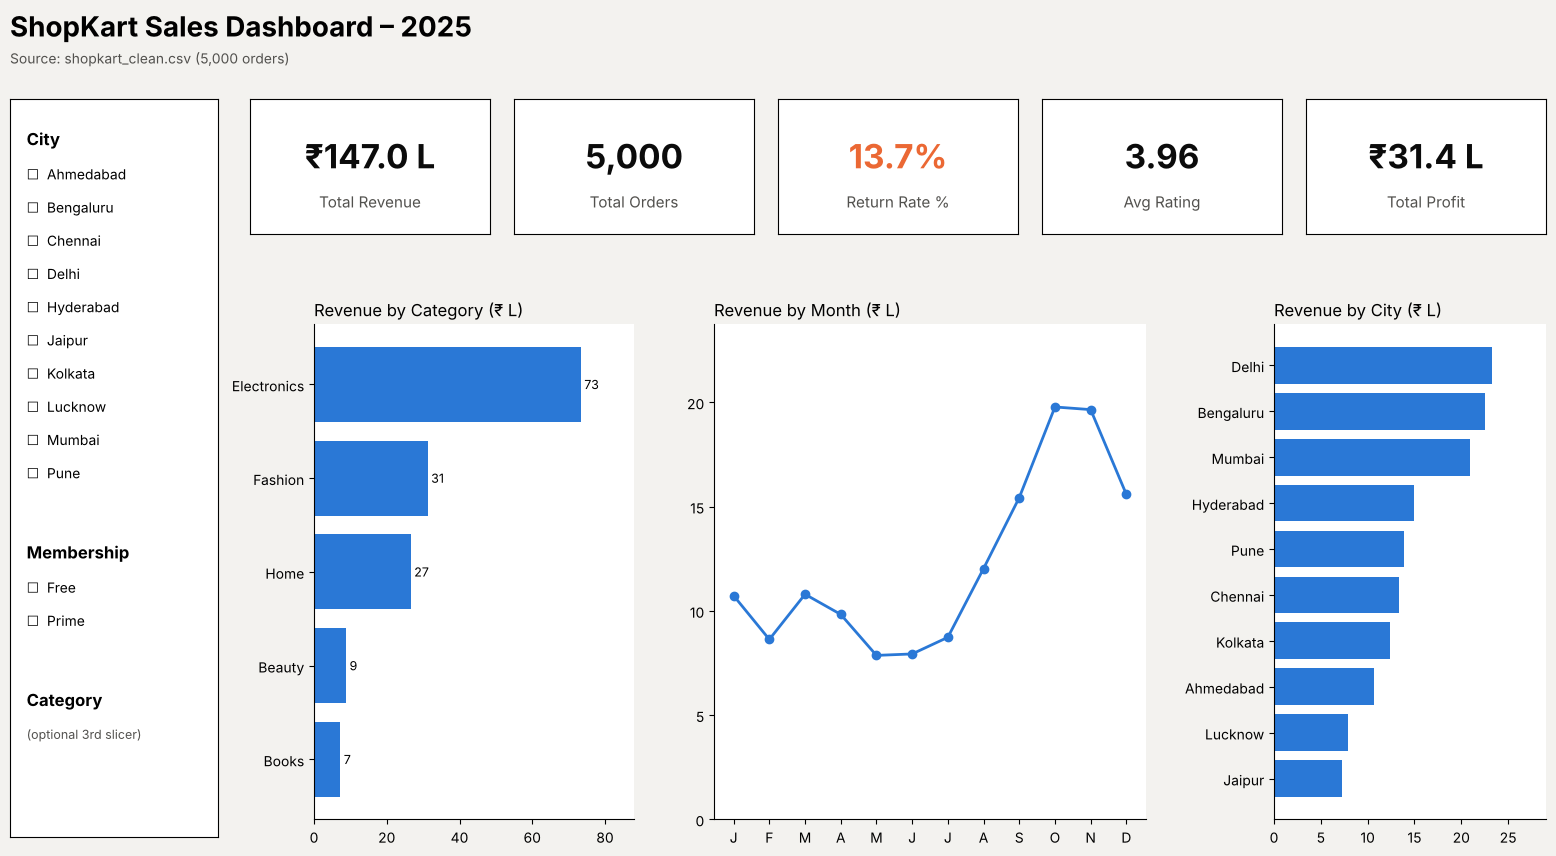

In [5]:
def lakh(x):
    return f"₹{x/100000:,.1f} L"

k = kpis(df)
cat = df.groupby("category")["revenue"].sum().sort_values() / 100000
month = df.groupby("order_month")["revenue"].sum() / 100000
city = df.groupby("city")["revenue"].sum().sort_values() / 100000
months = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

fig = plt.figure(figsize=(16, 9), facecolor="#f3f2ef")
fig.text(0.02, 0.95, "ShopKart Sales Dashboard – 2025", fontsize=20, weight="bold")
fig.text(0.02, 0.92, "Source: shopkart_clean.csv (5,000 orders)", fontsize=10, color="#52514e")

# Slicer panel (left)
sl = fig.add_axes([0.02, 0.06, 0.13, 0.82]); sl.set_xticks([]); sl.set_yticks([])
sl.set_facecolor("white")
sl.text(0.08, 0.96, "City", weight="bold", fontsize=12, va="top")
for i, c in enumerate(sorted(df["city"].unique())):
    sl.text(0.08, 0.91 - i * 0.045, "☐  " + c, fontsize=10, va="top")
sl.text(0.08, 0.40, "Membership", weight="bold", fontsize=12, va="top")
for i, m in enumerate(["Free", "Prime"]):
    sl.text(0.08, 0.35 - i * 0.045, "☐  " + m, fontsize=10, va="top")
sl.text(0.08, 0.20, "Category", weight="bold", fontsize=12, va="top")
sl.text(0.08, 0.15, "(optional 3rd slicer)", fontsize=9, color="#52514e", va="top")

# KPI cards (top row)
cards = [("Total Revenue", lakh(k["Total Revenue (₹)"])),
         ("Total Orders", f"{int(k['Total Orders']):,}"),
         ("Return Rate %", f"{k['Return Rate %']:.1f}%"),
         ("Avg Rating", f"{k['Avg Rating']:.2f}"),
         ("Total Profit", lakh(k["Total Profit (₹)"]))]
for i, (label, value) in enumerate(cards):
    ax = fig.add_axes([0.17 + i * 0.165, 0.73, 0.15, 0.15]); ax.set_xticks([]); ax.set_yticks([])
    ax.set_facecolor("white")
    ax.text(0.5, 0.58, value, ha="center", va="center", fontsize=24, weight="bold",
            color=HIGHLIGHT if label == "Return Rate %" else "#0b0b0b")
    ax.text(0.5, 0.2, label, ha="center", fontsize=11, color="#52514e")

# Chart 1: revenue by category
ax1 = fig.add_axes([0.21, 0.08, 0.2, 0.55])
ax1.barh(cat.index, cat.values, color=MAIN)
ax1.set_title("Revenue by Category (₹ L)", loc="left")
for i, v in enumerate(cat.values):
    ax1.text(v + 1, i, f"{v:.0f}", va="center", fontsize=9)
ax1.set_xlim(0, cat.max() * 1.2)

# Chart 2: revenue by month
ax2 = fig.add_axes([0.46, 0.08, 0.27, 0.55])
ax2.plot(month.index, month.values, marker="o", color=MAIN, linewidth=2)
ax2.set_xticks(month.index, months)
ax2.set_ylim(0, month.max() * 1.2)
ax2.set_title("Revenue by Month (₹ L)", loc="left")

# Chart 3: revenue by city
ax3 = fig.add_axes([0.81, 0.08, 0.17, 0.55])
ax3.barh(city.index, city.values, color=MAIN)
ax3.set_title("Revenue by City (₹ L)", loc="left")
ax3.set_xlim(0, city.max() * 1.25)

for a in (ax1, ax2, ax3):
    a.spines[["top", "right"]].set_visible(False)

plt.savefig("images/M08_dashboard_mockup.png", dpi=120, facecolor=fig.get_facecolor())
plt.show()